<a href="https://colab.research.google.com/github/stas22867/Python-Labs-New/blob/main/Lab4_Buhaienko.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4
**Тема:** Дослідження та візуалізація даних за допомогою Python  
**Мета:** Отримати базові навички використання Python для дослідження та візуалізації даних.  
**Виконав:** студент групи КН-225а Бугаєнко Станіслав Вячеславович  
**Варіант:** 1 (визначено за формулою $N = \text{ord}('Б') \pmod{3} + 1$) — *Дослідження втрат літаків*




In [17]:
import os

filename = "russia_losses_equipment.csv"

# Якщо файлу ще немає в сесії Colab, з'явиться кнопка "Вибрати файли" для завантаження
if not os.path.exists(filename):
    print("Будь ласка, оберіть файл 'russia_losses_equipment.csv' зі свого комп'ютера:")
    from google.colab import files
    uploaded = files.upload()

print(f"Файл '{filename}' готовий до обробки!")

Файл 'russia_losses_equipment.csv' готовий до обробки!


## Завдання 1 та 2
* **Завдання 1:** Створити функцію, яка приймає назву файлу та назву стовпця як параметр і повертає масив `numpy` зі значеннями стовпця (використовуючи `csv.reader()`, пропустивши заголовок).
* **Завдання 2:** Створити масив `numpy` зі значень стовпця «літак» (`aircraft`).

In [18]:
import csv
import numpy as np

def get_column_data(file_path, column_name):
    """
    Зчитує csv-файл за допомогою csv.reader(), пропускає заголовок
    і повертає масив numpy зі значеннями вказаного стовпця.
    """
    mapping = {
        'літак': 'aircraft',
        'літаки': 'aircraft',
        'aircraft': 'aircraft',
        'date': 'date'
    }
    target = mapping.get(column_name.lower().strip(), column_name.strip())

    with open(file_path, mode='r', encoding='utf-8') as f:
        reader = csv.reader(f)
        header = next(reader)  # Пропуск першого рядка (заголовків)

        header_lower = [h.lower() for h in header]
        if target.lower() in header_lower:
            col_idx = header_lower.index(target.lower())
        else:
            raise ValueError(f"Стовпець '{column_name}' не знайдено серед заголовків файлу!")

        data = [row[col_idx] for row in reader if len(row) > col_idx]

    try:
        arr = np.array(data, dtype=int)
    except ValueError:
        try:
            arr = np.array(data, dtype=float)
        except ValueError:
            arr = np.array(data, dtype=str)

    return arr

# Отримання даних
aircraft_losses = get_column_data(filename, "aircraft")
dates = get_column_data(filename, "date")

# ВАЖЛИВО: Якщо дати у файлі записані у зворотному порядку (від сьогодні до 2022 року),
# розгортаємо їх у правильному хронологічному напрямку (від першого дня війни до сьогодні)
if dates[0] > dates[-1]:
    dates = dates[::-1]
    aircraft_losses = aircraft_losses[::-1]

print("Завдання 2 виконано успішно.")
print(f"Кількість днів у наборі даних: {len(aircraft_losses)}")
print(f"Перша дата в наборі даних: {dates[0]}, втрати літаків: {aircraft_losses[0]}")
print(f"Остання дата в наборі даних: {dates[-1]}, втрати літаків: {aircraft_losses[-1]}")

Завдання 2 виконано успішно.
Кількість днів у наборі даних: 1731
Перша дата в наборі даних: 2022-02-25, втрати літаків: 10
Остання дата в наборі даних: 2026-11-21, втрати літаків: 452


## Завдання 3–6
* **Завдання 3:** Знайти добові втрати літаків (векторизовано, без використання циклів).
* **Завдання 4:** Знайти 3 найбільші добові втрати літаків.
* **Завдання 5:** Визначити, скільки літаків було збито влітку 2022 року (01.06.2022 – 31.08.2022).
* **Завдання 6:** Знайти середнє значення втрат авіації за останні 300 днів війни.

In [19]:
# Завдання 3: Добові втрати літаків
def get_daily_losses(cumulative_losses):
    """
    Знаходить добові втрати як різницю кумулятивних втрат за допомогою зрізів numpy (без циклів).
    """
    daily = np.empty_like(cumulative_losses)
    daily[0] = cumulative_losses[0]
    daily[1:] = cumulative_losses[1:] - cumulative_losses[:-1]

    # Корекція на випадок оновлень ретроспективних даних
    daily = np.maximum(daily, 0)
    return daily

# Завдання 4: 3 найбільші добові втрати
def get_top_daily_losses(daily_losses, top_n=3):
    """
    Знаходить найбільші добові втрати за допомогою сортування numpy.
    """
    sorted_losses = np.sort(daily_losses)
    return sorted_losses[-top_n:][::-1]

# Завдання 5: Втрати влітку 2022 року
def get_losses_summer_2022(daily_losses, dates_arr):
    """
    Визначає втрати влітку 2022 року за допомогою векторизованої булевої маски.
    """
    summer_mask = (dates_arr >= "2022-06-01") & (dates_arr <= "2022-08-31")
    return np.sum(daily_losses[summer_mask])

# Завдання 6: Середнє значення за останні 300 днів
def get_mean_losses_last_days(daily_losses, days=300):
    """
    Обчислює середнє значення втрат за останні N днів за допомогою зрізу та np.mean().
    """
    return np.mean(daily_losses[-days:])

# Виклики функцій та виведення результатів:
daily_aircraft = get_daily_losses(aircraft_losses)
top_3_losses = get_top_daily_losses(daily_aircraft, 3)
summer_2022 = get_losses_summer_2022(daily_aircraft, dates)
mean_300 = get_mean_losses_last_days(daily_aircraft, 300)

print(f"3. Перші 10 значень добових втрат: {daily_aircraft[:10]}")
print(f"4. Три найбільші добові втрати літаків: {top_3_losses}")
print(f"5. Кількість літаків, збитих влітку 2022 року: {summer_2022}")
print(f"6. Середнє значення втрат авіації за останні 300 днів війни: {mean_300:.3f} літаків/день")

3. Перші 10 значень добових втрат: [10 17  0  2  0  1  0  3  6  5]
4. Три найбільші добові втрати літаків: [41 17 16]
5. Кількість літаків, збитих влітку 2022 року: 26
6. Середнє значення втрат авіації за останні 300 днів війни: 0.060 літаків/день


## Завдання 7
**Постановка задачі:**  
Створити графік втрат літаків за перший рік війни (починаючи з першої дати в наборі даних), що відповідає всім вимогам пункту 5 (пунктирна лінія, назва, підписи осей, сітка із заданим типом і кольором, легенда, роздільна здатність 100 dpi, розмір 16х8 дюймів, збереження у PNG).

Графік збережено у файл 'aircraft_losses_first_year.png'!


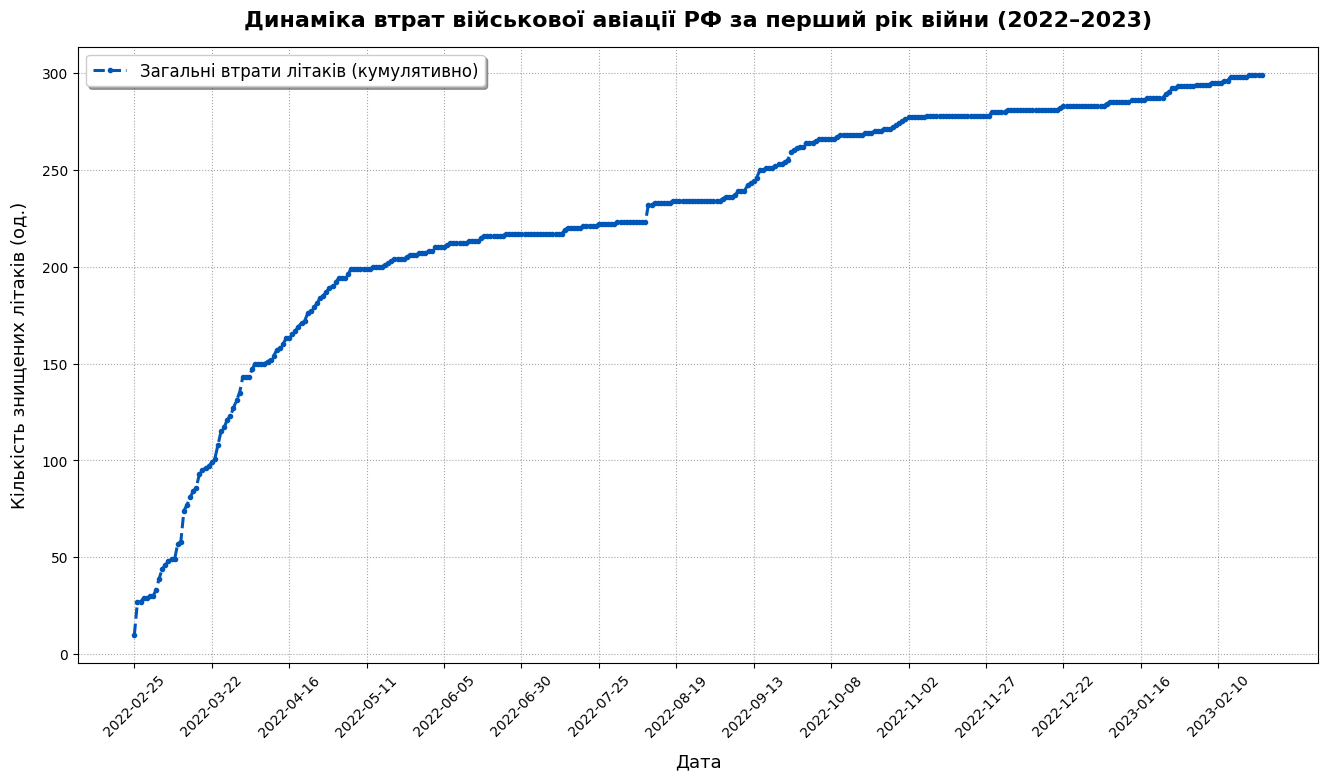

In [20]:
import matplotlib.pyplot as plt

def plot_aircraft_losses_first_year(cumulative_losses, dates_arr, save_file="aircraft_losses_first_year.png"):
    """
    Будує графік втрат літаків за перший рік війни та зберігає його у файл.
    """
    # Перший рік війни (перші 365 днів від першої дати)
    first_year_count = min(365, len(dates_arr))
    x_dates = dates_arr[:first_year_count]
    y_losses = cumulative_losses[:first_year_count]

    # 5.f Розмір графіка 16x8 дюймів, розподільна здатність 100 dpi
    plt.figure(figsize=(16, 8), dpi=100)

    # 5.a Пунктирна лінія (linestyle='--')
    # 5.b Підпис графіка (label)
    plt.plot(x_dates, y_losses, linestyle='--', color='#0057B7', linewidth=2.2,
             marker='o', markersize=3, label='Загальні втрати літаків (кумулятивно)')

    # 5.e Назва графіка, позначки осей і значення на осях
    plt.title("Динаміка втрат військової авіації РФ за перший рік війни (2022–2023)",
              fontsize=16, fontweight='bold', pad=15)
    plt.xlabel("Дата", fontsize=13, labelpad=10)
    plt.ylabel("Кількість знищених літаків (од.)", fontsize=13, labelpad=10)

    # Налаштування кроку підписів на осі X для гарного читання дат
    step = 25
    plt.xticks(ticks=range(0, first_year_count, step),
               labels=x_dates[::step],
               rotation=45, fontsize=10)
    plt.yticks(fontsize=10)

    # 5.d Сітка, колір і тип ліній
    plt.grid(True, color='gray', linestyle=':', linewidth=0.8, alpha=0.7)

    # 5.c Легенда
    plt.legend(loc='upper left', fontsize=12, frameon=True, shadow=True)

    # 5.g Збереження графіка у файл формату png
    plt.savefig(save_file, format='png', dpi=100, bbox_inches='tight')
    print(f"Графік збережено у файл '{save_file}'!")

    plt.show()

# Виклик функції побудови графіка
plot_aircraft_losses_first_year(aircraft_losses, dates)

## Висновки
Під час виконання лабораторної роботи №7:
1. Отримано практичні навички читання даних із файлів формату `.csv` засобами стандартного модуля `csv.reader()`.
2. Засвоєно роботу з масивами бібліотеки `numpy`, опановано роботу з числовими та рядковими типами даних.
3. Досліджено використання векторних операцій та зрізів (`slicing`) замість звичайних ітераційних циклів для ефективної обробки великих наборів даних (обчислення добової динаміки через різниці кумулятивних значень, сортування та булеві маски дат).
4. Опановано інструментарій бібліотеки `matplotlib` для побудови інформативних графіків згідно з інженерними вимогами (налаштування типу лінії, розміру полотна, сітки, легенди та експорт візуалізації у файл `.png`).